# Walk exploration (figures)

Synthetic plots from **precomputed walk caches**. Generate graphs and caches via `1_synthetic_walk_exploration_data_processing.ipynb`, then run the cells below.


In [1]:
from pathlib import Path
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RESULTS = Path("results") / "walk_exploration"
RESULTS.mkdir(parents=True, exist_ok=True)

RESULTS_IMAGES = Path("results") / "images"
RESULTS_IMAGES.mkdir(parents=True, exist_ok=True)


PQ_GRID_COV = [
    (0.25, 4), (0.5, 2), (1, 2), (1, 1), (0.5, 0.5), (2, 1),
    (2, 0.5), (4, 0.25)
]

GAMMAS = [-1.0, 1.0]
N_GRAPHS = 5

PQ_GRID_TRANS = [
    (0.25, 4), (0.5, 2), (1, 1), (0.5, 0.5),
    (2, 0.5), (4, 0.25)
]

GAMMA_COMM = -1.0
PQ_JOINT = [(0.25, 4), (1, 1), (4, 0.25)]


def _load_pickle(p: Path):
    with open(p, "rb") as f:
        return pickle.load(f)


walk_5_cache_cov = _load_pickle(RESULTS / "walk_cache_cov_ncom1_avgdeg5.pkl")
walk_20_cache_cov = _load_pickle(RESULTS / "walk_cache_cov_ncom1_avgdeg20.pkl")

colors = plt.get_cmap("Set2").colors


In [ ]:
def plot_pq_gamma_coverage(
    walk_cache,
    results_dir: Path,
    *,
    metric_key: str,
    ylabel: str,
    suptitle: str,
    png_name: str,
    n_graphs: int = N_GRAPHS,
):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, gamma_val in zip(axes, GAMMAS):
        for i, (p_i, q_i) in enumerate(PQ_GRID_COV[::-1]):
            curves = [walk_cache[(gamma_val, p_i, q_i, g)][metric_key] for g in range(n_graphs)]
            C = np.vstack(curves)
            mean_c, std_c = C.mean(axis=0), C.std(axis=0)
            steps = np.arange(1, len(mean_c) + 1)
            c = colors[i % len(colors)]
            ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
            ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.2)
        ax.set_xlabel("Walk Step", fontsize=11)
        ax.set_title(f"$\\gamma={gamma_val:.0f}$", fontsize=12)
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(ylabel, fontsize=11)
    axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
    axes[1].set_ylim(0.0, 101)
    fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    fig.savefig(results_dir / png_name, dpi=300, bbox_inches="tight")
    plt.show()


def plot_stage1_barplot(
    walk_cache, results_dir: Path, *, avgdeg_label: str, file_tag: str, n_graphs: int = N_GRAPHS
):
    gamma_diag = -1.0
    case_names = ["same hyperedge", "middle case", "other case"]
    group_labels = [f"p={p_i}, q={q_i}" for (p_i, q_i) in PQ_GRID_TRANS]

    selected_vals = []
    possible_vals = []
    for p_i, q_i in PQ_GRID_TRANS:
        selected_curves = [walk_cache[(gamma_diag, p_i, q_i, g)]["case"] for g in range(n_graphs)]
        possible_curves = [walk_cache[(gamma_diag, p_i, q_i, g)]["possible"] for g in range(n_graphs)]
        selected_vals.append(np.stack(selected_curves, axis=0).mean(axis=(0, 1)))
        possible_vals.append(np.stack(possible_curves, axis=0).mean(axis=(0, 1)))

    selected_vals = np.asarray(selected_vals)
    possible_vals = np.asarray(possible_vals)

    rows = []
    for i, (p_i, q_i) in enumerate(PQ_GRID_TRANS):
        rows.append({
            "p": p_i, "q": q_i,
            "selected_same": selected_vals[i, 0], "selected_middle": selected_vals[i, 1], "selected_other": selected_vals[i, 2],
            "possible_same": possible_vals[i, 0], "possible_middle": possible_vals[i, 1], "possible_other": possible_vals[i, 2],
        })

    avail_one = possible_vals.mean(axis=0)
    x = np.arange(len(PQ_GRID_TRANS))
    bar_w = 0.26
    case_colors = ["#66c2a5", "#fc8d62", "#8da0cb"]
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [4, 1]})
    for j, name in enumerate(case_names):
        axes[0].bar(x + (j - 1) * bar_w, selected_vals[:, j], width=bar_w, color=case_colors[j], label=name)
    axes[0].set_ylim(0.0, 1.05)
    axes[0].set_ylabel("Mean Fraction", fontsize=11)
    axes[0].set_xlabel("Hyperparameter Set (p, q)", fontsize=11)
    axes[0].set_title(f"Selection, {avgdeg_label}", fontsize=12)
    axes[0].grid(axis="y", alpha=0.3)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(group_labels, rotation=20, ha="right")
    axes[0].legend(frameon=False, loc="upper left")

    x2 = np.array([0.0])
    for j, _ in enumerate(case_names):
        axes[1].bar(x2 + (j - 1) * bar_w, [avail_one[j]], width=bar_w, color=case_colors[j])
    axes[1].set_ylim(0.0, 1.05)
    axes[1].set_title("Availability", fontsize=12)
    axes[1].grid(axis="y", alpha=0.3)
    axes[1].set_xticks([0.0])
    axes[1].set_xticklabels(["all (p,q)"])
    axes[1].tick_params(axis="y", left=False, labelleft=False)

    fig.tight_layout()
    fig.savefig(
        results_dir / f"synth_transition_cases_{file_tag}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


def plot_joint_high_low_panel(ax, walk_cache_high, walk_cache_low, pq_joint: list, n_steps_plot: int):
    for i, (p_i, q_i) in enumerate(pq_joint):
        c = colors[i % len(colors)]
        key = (GAMMA_COMM, p_i, q_i)
        intra_h = [walk_cache_high[(*key, g)]["intra"][:n_steps_plot] for g in range(N_GRAPHS)]
        inter_h = [walk_cache_high[(*key, g)]["inter"][:n_steps_plot] for g in range(N_GRAPHS)]
        mean_intra_h = np.vstack(intra_h).mean(axis=0)
        mean_inter_h = np.vstack(inter_h).mean(axis=0)
        total_h = mean_intra_h + mean_inter_h
        ratio_h = np.divide(mean_intra_h, total_h, out=np.zeros_like(mean_intra_h), where=total_h > 0)
        intra_l = [walk_cache_low[(*key, g)]["intra"][:n_steps_plot] for g in range(N_GRAPHS)]
        inter_l = [walk_cache_low[(*key, g)]["inter"][:n_steps_plot] for g in range(N_GRAPHS)]
        mean_intra_l = np.vstack(intra_l).mean(axis=0)
        mean_inter_l = np.vstack(inter_l).mean(axis=0)
        total_l = mean_intra_l + mean_inter_l
        ratio_l = np.divide(mean_intra_l, total_l, out=np.zeros_like(mean_intra_l), where=total_l > 0)
        ax.plot(np.arange(len(ratio_h)), ratio_h, color=c, lw=2, linestyle="-")
        ax.plot(np.arange(len(ratio_l)), ratio_l, color=c, lw=2, linestyle="--")
    ax.set_xlabel("Walk Step")
    ax.set_ylim(0.4, 1.02)
    ax.grid(alpha=0.25)




### Coverage (p, q) × $\gamma$


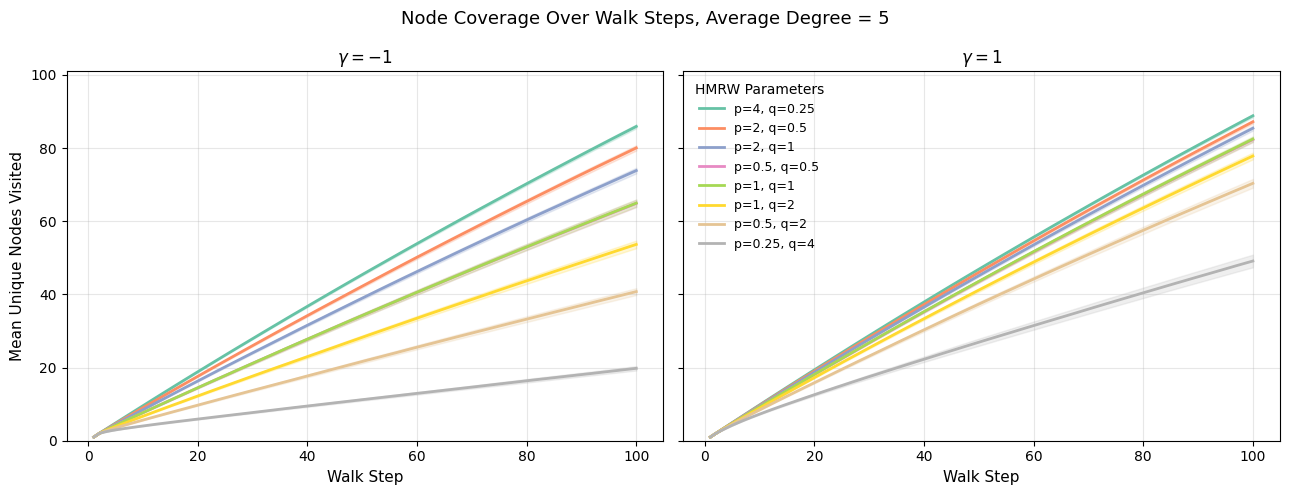

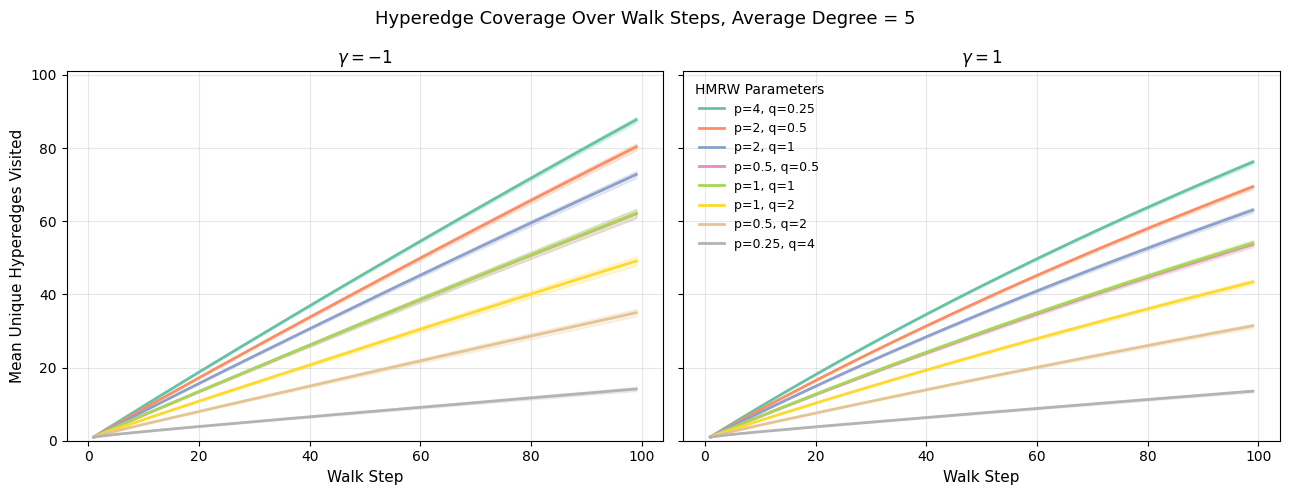

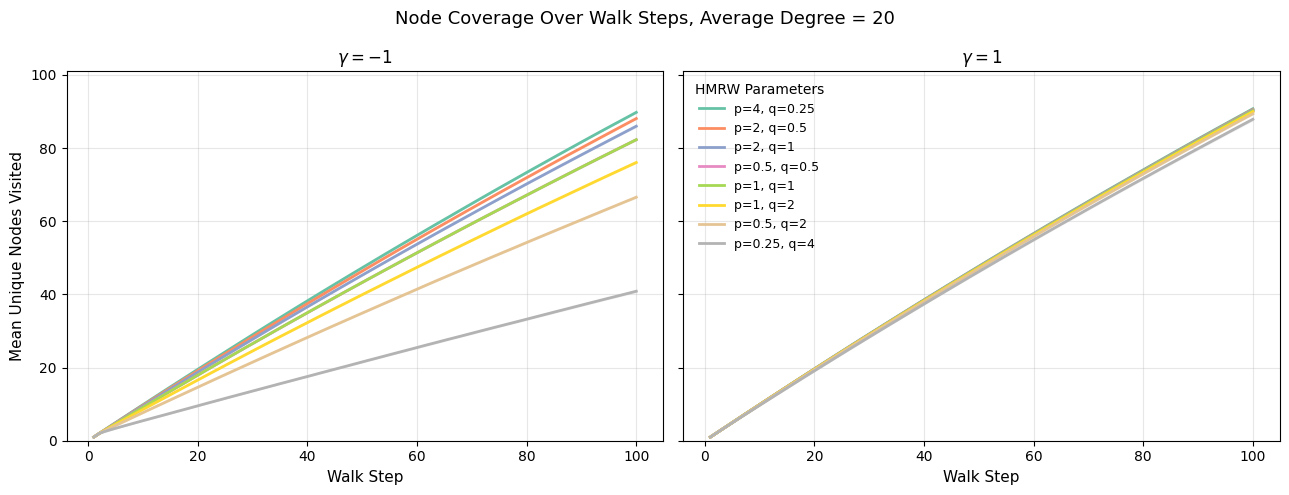

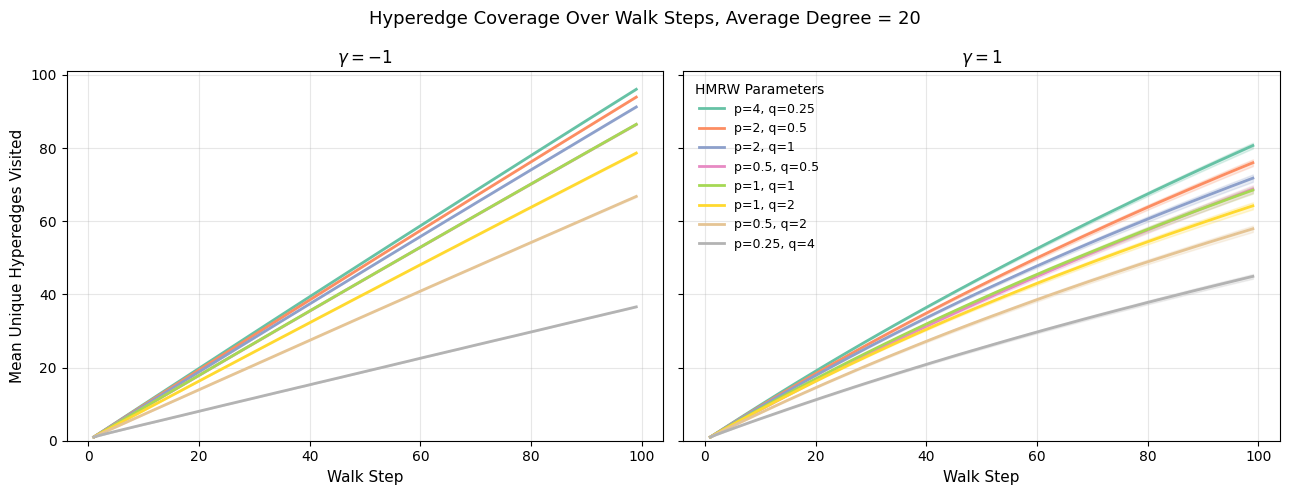

In [3]:
# Average degree 5
plot_pq_gamma_coverage(
    walk_5_cache_cov, RESULTS_IMAGES,
    metric_key="node",
    ylabel="Mean Unique Nodes Visited",
    suptitle="Node Coverage Over Walk Steps, Average Degree = 5",
    png_name="synth_node_coverage_ncom1_avgdeg5.png",
)
plot_pq_gamma_coverage(
    walk_5_cache_cov, RESULTS_IMAGES,
    metric_key="hyper",
    ylabel="Mean Unique Hyperedges Visited",
    suptitle="Hyperedge Coverage Over Walk Steps, Average Degree = 5",
    png_name="synth_hedge_coverage_ncom1_avgdeg5.png",
)

# Average degree 20
plot_pq_gamma_coverage(
    walk_20_cache_cov, RESULTS_IMAGES,
    metric_key="node",
    ylabel="Mean Unique Nodes Visited",
    suptitle="Node Coverage Over Walk Steps, Average Degree = 20",
    png_name="synth_node_coverage_ncom1_avgdeg20.png",
)
plot_pq_gamma_coverage(
    walk_20_cache_cov, RESULTS_IMAGES,
    metric_key="hyper",
    ylabel="Mean Unique Hyperedges Visited",
    suptitle="Hyperedge Coverage Over Walk Steps, Average Degree = 20",
    png_name="synth_hedge_coverage_ncom1_avgdeg20.png",
)

### Stage-1 transition diagnostics


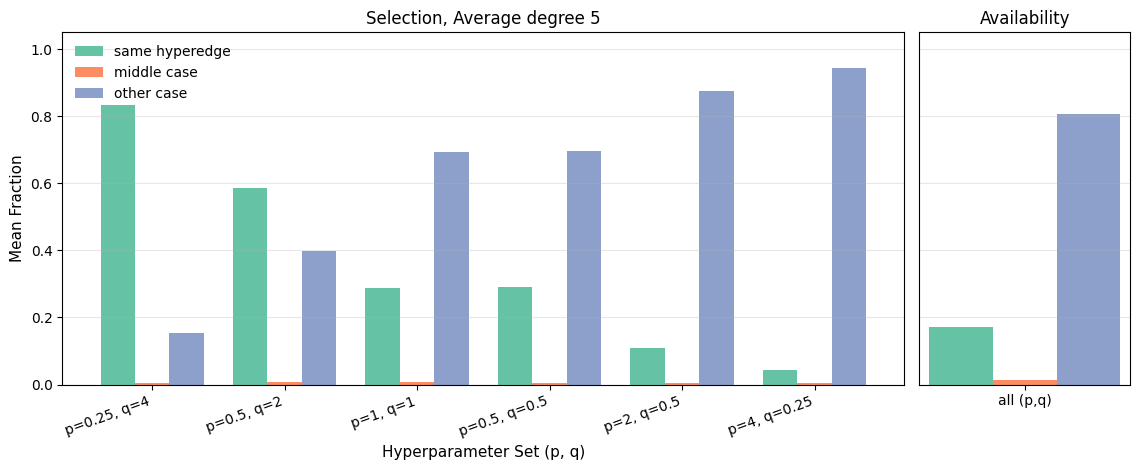

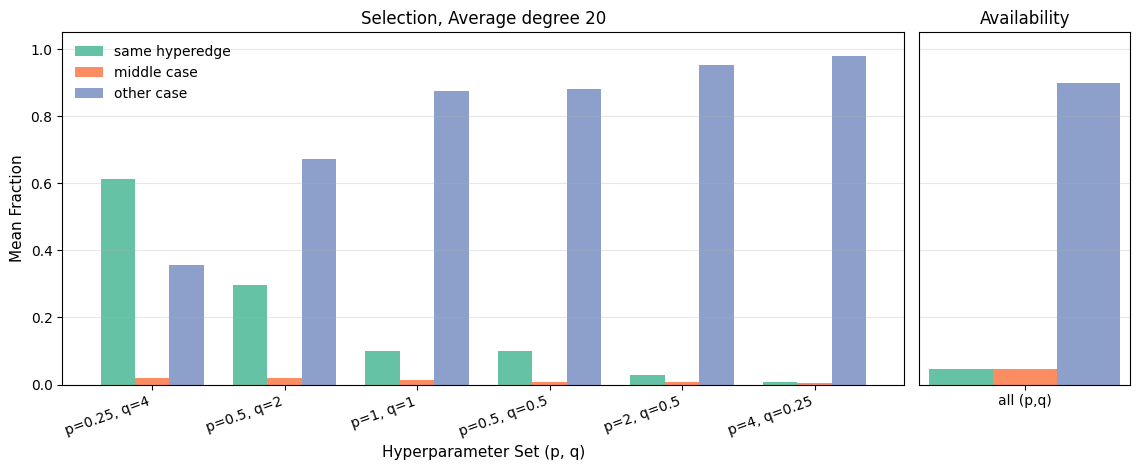

In [4]:
plot_stage1_barplot(
    walk_5_cache_cov, RESULTS_IMAGES, avgdeg_label="Average degree 5", file_tag="ncom1_avgdeg5"
)
plot_stage1_barplot(
    walk_20_cache_cov, RESULTS_IMAGES, avgdeg_label="Average degree 20", file_tag="ncom1_avgdeg20"
)


### Community mix (intra / (intra + inter))


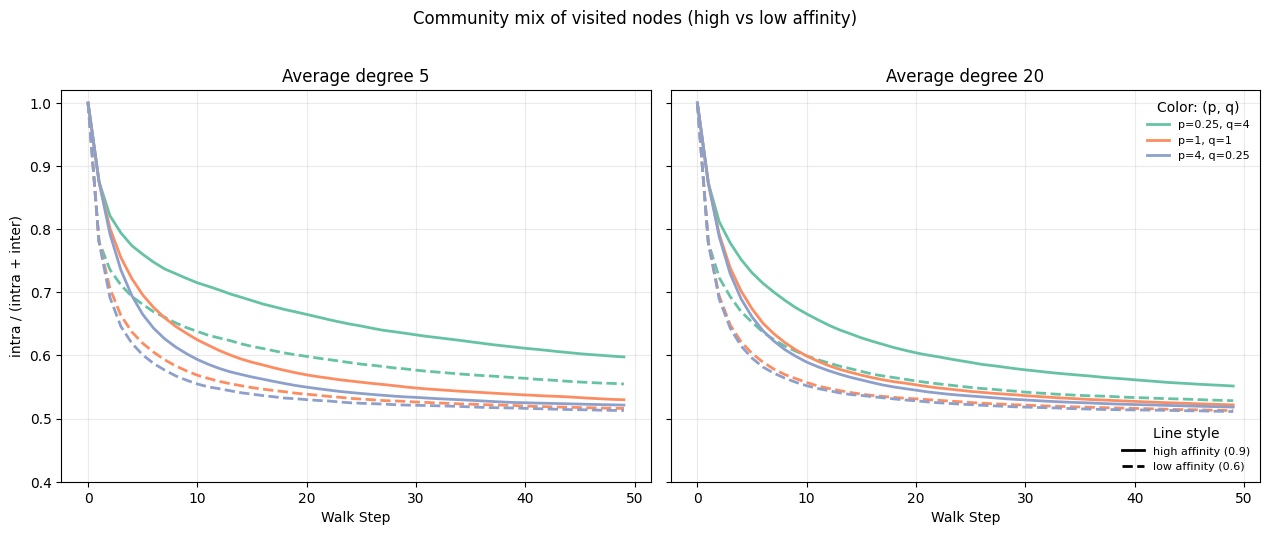

In [ ]:
# Joint: avgdeg 5 vs 20 (two panels)
n_steps_plot = 50

w5h = _load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg5_aff09.pkl")
w5l = _load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg5_aff06.pkl")
w20h = _load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg20_aff09.pkl")
w20l = _load_pickle(RESULTS / "walk_cache_cov_ncom2_avgdeg20_aff06.pkl")

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2), sharey=True)
plot_joint_high_low_panel(axes[0], w5h, w5l, PQ_JOINT, n_steps_plot)
axes[0].set_ylabel(r"intra / (intra + inter)")
axes[0].set_title("Average degree 5")
plot_joint_high_low_panel(axes[1], w20h, w20l, PQ_JOINT, n_steps_plot)
axes[1].set_title("Average degree 20")

color_handles = [
    Line2D([0], [0], color=colors[i % len(colors)], lw=2, linestyle="-", label=f"p={p_i}, q={q_i}")
    for i, (p_i, q_i) in enumerate(PQ_JOINT)
]
style_handles = [
    Line2D([0], [0], color="black", lw=2, linestyle="-", label="high affinity (0.9)"),
    Line2D([0], [0], color="black", lw=2, linestyle="--", label="low affinity (0.6)"),
]
leg1 = axes[1].legend(handles=color_handles, title="Color: (p, q)", frameon=False, fontsize=8, loc="upper right")
axes[1].add_artist(leg1)
axes[1].legend(handles=style_handles, title="Line style", frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Community mix of visited nodes (high vs low affinity)", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(RESULTS_IMAGES / "synth_community_ncom2_avgdeg5_20_aff_09_06.png", dpi=300, bbox_inches="tight")
plt.show()


### Hypergraph structure (ncom = 1)

Node degrees use `H.degree_distribution()` (mapping degree → count; expanded per graph for histograms). Hyperedge sizes use `H.get_sizes()`. For **average degree 5** and **average degree 20**, each row has two histograms: **mean of per-graph normalized densities** over all synthetic graphs (shared integer bins). Loads `hypergraphs_ncom1_avgdeg5.pkl` and `hypergraphs_ncom1_avgdeg20.pkl` from `1_synthetic_walk_exploration_data_processing.ipynb`.

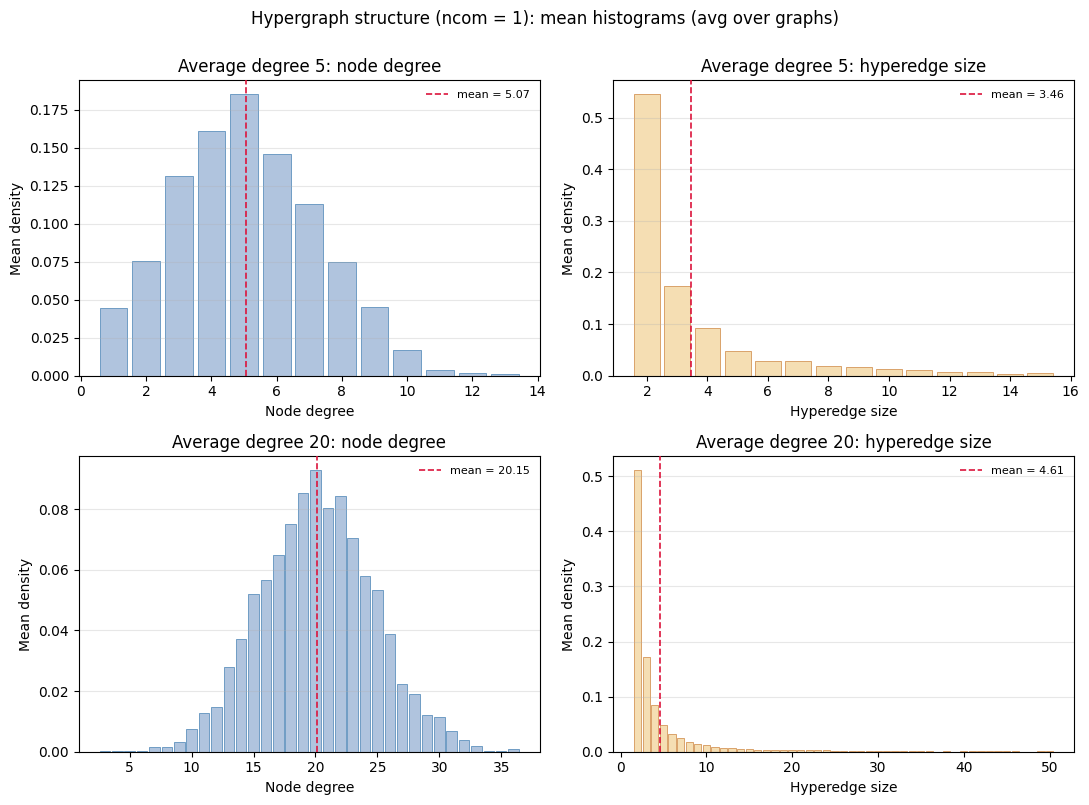

In [ ]:
def mean_density_histogram(ax, samples_per_graph, *, color, edgecolor, title, ylabel, xlabel):
    # Mean of per-graph normalized histograms (same bins; each graph integrates to 1).
    pooled = np.concatenate(samples_per_graph)
    v_min, v_max = int(pooled.min()), int(pooled.max())
    bins = np.arange(v_min - 0.5, v_max + 1.5, 1.0)
    hists = [np.histogram(s, bins=bins, density=True)[0] for s in samples_per_graph]
    mean_h = np.mean(hists, axis=0)
    centers = (bins[:-1] + bins[1:]) / 2
    ax.bar(centers, mean_h, width=0.85, color=color, edgecolor=edgecolor, linewidth=0.5)
    mu = float(np.mean(pooled))
    ax.axvline(mu, color="crimson", linestyle="--", linewidth=1.2, zorder=3, label=f"mean = {mu:.2f}")
    ax.legend(frameon=False, fontsize=8, loc="best")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)


def plot_hypergraph_structure_ncom1(Hs_deg5, Hs_deg20, results_dir: Path):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for row, (Hs, row_title) in enumerate(
        [(Hs_deg5, "Average degree 5"), (Hs_deg20, "Average degree 20")]
    ):
        deg = [
            np.array([d for d, c in H.degree_distribution().items() for _ in range(int(c))])
            for H in Hs
        ]
        sz = [np.asarray(H.get_sizes(), dtype=float) for H in Hs]
        mean_density_histogram(
            axes[row, 0], deg,
            color="lightsteelblue", edgecolor="steelblue",
            title=f"{row_title}: node degree",
            ylabel="Mean density",
            xlabel="Node degree",
        )
        mean_density_histogram(
            axes[row, 1], sz,
            color="wheat", edgecolor="peru",
            title=f"{row_title}: hyperedge size",
            ylabel="Mean density",
            xlabel="Hyperedge size",
        )

    fig.suptitle(
        "Hypergraph structure (ncom = 1): mean histograms (avg over graphs)",
        fontsize=12,
        y=1.0,
    )
    fig.tight_layout()
    fig.savefig(results_dir / "synth_hypergraph_structure_ncom1_avgdeg5_20.png", dpi=300, bbox_inches="tight")
    plt.show()


Hs_ncom1_deg5 = _load_pickle(RESULTS / "hypergraphs_ncom1_avgdeg5.pkl")
Hs_ncom1_deg20 = _load_pickle(RESULTS / "hypergraphs_ncom1_avgdeg20.pkl")
plot_hypergraph_structure_ncom1(Hs_ncom1_deg5, Hs_ncom1_deg20, RESULTS_IMAGES)
